数据规模： (568454, 10)

数据类型：
Id                        int64
ProductId                   str
UserId                      str
ProfileName                 str
HelpfulnessNumerator      int64
HelpfulnessDenominator    int64
Score                     int64
Time                      int64
Summary                     str
Text                        str
dtype: object

缺失值：
Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

评分分布：
Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


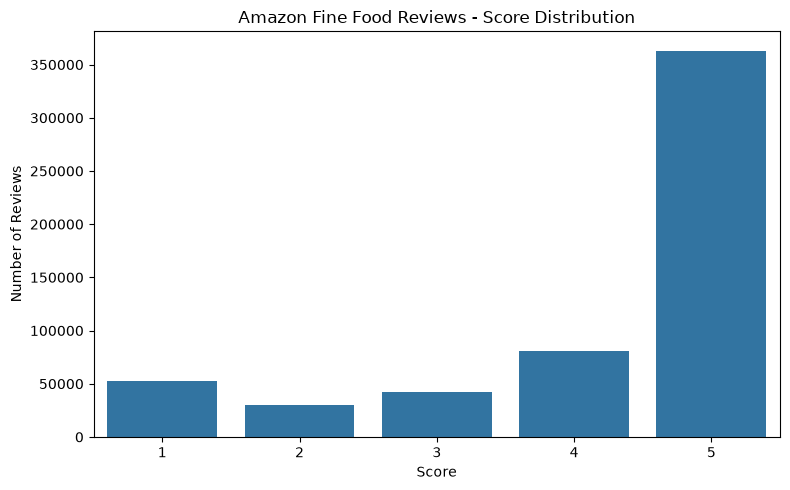

重复行数： 0
Text 缺失： 0
Score 缺失： 0
评分取值： [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

评论长度统计：
count    568454.000000
mean        436.222083
std         445.339741
min          12.000000
25%         179.000000
50%         302.000000
75%         527.000000
max       21409.000000
Name: text_length, dtype: float64

有用性投票异常记录： 2


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/Reviews.csv")

print("数据规模：", df.shape)
print("\n数据类型：")
print(df.dtypes)
print("\n缺失值：")
print(df.isnull().sum())
print("\n评分分布：")
print(df["Score"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Score")
plt.title("Amazon Fine Food Reviews - Score Distribution")
plt.xlabel("Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig("../results/figures/score_distribution.png", dpi=300)
plt.show()

# 1. 检查重复记录
print("重复行数：", df.duplicated().sum())

# 2. 检查关键字段缺失
print("Text 缺失：", df["Text"].isnull().sum())
print("Score 缺失：", df["Score"].isnull().sum())

# 3. 检查评分范围
print("评分取值：", sorted(df["Score"].dropna().unique()))

# 4. 检查评论长度
df["text_length"] = df["Text"].fillna("").str.len()

print("\n评论长度统计：")
print(df["text_length"].describe())

# 5. 检查有用性投票异常
invalid_helpfulness = (
    df["HelpfulnessNumerator"] >
    df["HelpfulnessDenominator"]
).sum()

print("\n有用性投票异常记录：", invalid_helpfulness)